In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics scikit-learn opencv-python pyyaml seaborn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 5.9 MB/s eta 0:00:00


In [ ]:
import os, sys, cv2, yaml, time, joblib, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, ConfusionMatrixDisplay,
)
from ultralytics import YOLO

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IN_COLAB = 'google.colab' in sys.modules or 'COLAB_GPU' in os.environ

if IN_COLAB:
    DRIVE_BASE    = Path('/content/drive/MyDrive/ConstructionSiteAi')
    DATA_DIR      = DRIVE_BASE / 'ConstructionSiteSafetyImageDatasetRoboflow' / 'css-data'
    DATA_YAML     = (DRIVE_BASE / 'ConstructionSiteSafetyImageDatasetRoboflow'
                     / 'results_yolov8n_100e' / 'kaggle' / 'working' / 'ppe_data.yaml')
    YOLO_WEIGHTS  = (DRIVE_BASE / 'runs' / 'detect' / 'runs' / 'ppe'
                     / 'yolo_ppe_baseline' / 'weights' / 'best.pt')
    AE_CHECKPOINT = (DRIVE_BASE / 'data' / 'processed' / 'features'
                     / 'ae_v2' / 'autoencoder_v2_best.pth')
    OUT_DIR       = DRIVE_BASE / 'classification_results'
else:
    # Flexible local path detection
    base_candidates = [
        Path(r'C:/Users/mrpat/Downloads/Constructio_Site_AI/ConstructionSiteSafetyImageDatasetRoboflow'),
        Path(r'C:/Desktop/ConstructionAI/Constructionsite_ai'),
        Path(os.getcwd()).parent,
    ]
    DRIVE_BASE = next((p for p in base_candidates if p.exists()), base_candidates[0])
    
    data_candidates = [
        Path(r'C:/Users/mrpat/Downloads/Constructio_Site_AI/ConstructionSiteSafetyImageDatasetRoboflow/css-data'),
        DRIVE_BASE / 'css-data',
        DRIVE_BASE / 'data',
    ]
    DATA_DIR = next((p for p in data_candidates if p.exists()), data_candidates[0])
    
    yaml_candidates = [
        Path(r'C:/Users/mrpat/Downloads/Constructio_Site_AI/ConstructionSiteSafetyImageDatasetRoboflow/results_yolov8n_100e/kaggle/working/ppe_data.yaml'),
        DRIVE_BASE / 'results_yolov8n_100e' / 'kaggle' / 'working' / 'ppe_data.yaml',
    ]
    DATA_YAML = next((p for p in yaml_candidates if p.exists()), yaml_candidates[0])
    
    yolo_candidates = [
        Path(r'C:/Users/mrpat/Downloads/Constructio_Site_AI/ConstructionSiteSafetyImageDatasetRoboflow/results_yolov8n_100e/kaggle/working/runs/detect/train/weights/best.pt'),
        DRIVE_BASE / 'weights' / 'best.pt',
    ]
    YOLO_WEIGHTS = next((p for p in yolo_candidates if p.exists()), yolo_candidates[0])
    
    ae_candidates = [
        Path(r'C:/Desktop/ConstructionAI/Constructionsite_ai/weights/autoencoder_v2_best.pth'),
        Path(r'C:/Users/mrpat/Downloads/Constructio_Site_AI/data/processed/features/ae_v2/autoencoder_v2_best.pth'),
        DRIVE_BASE / 'weights' / 'autoencoder_v2_best.pth',
    ]
    AE_CHECKPOINT = next((p for p in ae_candidates if p.exists()), ae_candidates[0])
    
    OUT_DIR = Path(r'C:/Desktop/ConstructionAI/Constructionsite_ai/weights')

OUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE      = 128
BASE_CHANNELS = 32
NUM_CLASSES   = 10
DEVICE        = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Device       : {DEVICE}')
print(f'Data dir     : {DATA_DIR}')
print(f'AE checkpoint: {AE_CHECKPOINT}')
print(f'Output dir   : {OUT_DIR}')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device       : cpu
Data dir     : /content/drive/MyDrive/ConstructionSiteAi/ConstructionSiteSafetyImageDatasetRoboflow/css-data
AE checkpoint: /content/drive/MyDrive/ConstructionSiteAi/data/processed/features/ae_v2/autoencoder_v2_best.pth
Output dir   : /content/drive/MyDrive/ConstructionSiteAi/classification_results


In [ ]:
import os
import torch

# NOTE: Ensure you run cell n7veUEOcgruS (defining AutoencoderV2)
# and cell KCDJ-KL3Qspn (defining EncoderClassifier) before running this cell.
try:
    model = EncoderClassifier(ae_model, num_classes=NUM_CLASSES).to(DEVICE)
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

    start_epoch = 0
    checkpoint_path = "/content/drive/MyDrive/ConstructionSiteAi/model_checkpoint.pth"

    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        start_epoch = checkpoint["epoch"] + 1
        print(f"Resuming training from epoch {start_epoch}")
except NameError as e:
    print(f"Initialization error: {e}. please execute cells n7veUEOcgruS and KCDJ-KL3Qspn first!")

Initialization error: name 'EncoderClassifier' is not defined. please execute cells n7veUEOcgruS and KCDJ-KL3Qspn first!


In [ ]:
import torch

# At the end of every epoch:
checkpoint = {
    'epoch': epoch,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': loss,
}
torch.save(checkpoint, '/content/drive/MyDrive/ConstructionSiteAi/model_checkpoint.pth')

NameError: name 'epoch' is not defined

In [ ]:
if not DATA_YAML.exists():
    raise FileNotFoundError(f"Dataset YAML not found at: {DATA_YAML}")

with open(DATA_YAML, "r", encoding="utf-8") as fh:
    cfg = yaml.safe_load(fh)

NAMES = cfg["names"]
if isinstance(NAMES, dict):
    NAMES = [NAMES[k] for k in sorted(NAMES, key=lambda x: int(x))]

NUM_CLASSES = len(NAMES)
print(f"Classes ({NUM_CLASSES}): {NAMES}")


Classes (10): ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']


In [ ]:
class ConvBlock(nn.Module):
    # Identical to 02_Autoencoder.ipynb
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.1, inplace=True),
        )
    def forward(self, x):
        return self.block(x)


class AutoencoderV2(nn.Module):
    # Identical to 02_Autoencoder.ipynb
    def __init__(self, base=32):
        super().__init__()
        self.enc1 = ConvBlock(3,         base)
        self.enc2 = ConvBlock(base,      base * 2)
        self.enc3 = ConvBlock(base * 2,  base * 4)
        self.enc4 = ConvBlock(base * 4,  base * 4)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(base * 4, base * 4)
        self.up4  = nn.ConvTranspose2d(base * 4, base * 4, 2, 2)
        self.dec4 = ConvBlock(base * 8, base * 4)
        self.up3  = nn.ConvTranspose2d(base * 4, base * 4, 2, 2)
        self.dec3 = ConvBlock(base * 8, base * 2)
        self.up2  = nn.ConvTranspose2d(base * 2, base * 2, 2, 2)
        self.dec2 = ConvBlock(base * 4, base)
        self.up1  = nn.ConvTranspose2d(base, base, 2, 2)
        self.dec1 = ConvBlock(base * 2, base)
        self.output = nn.Sequential(
            nn.Conv2d(base, 3, kernel_size=1),
            nn.Sigmoid(),
        )

    def encode(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        z  = self.bottleneck(self.pool(e4))
        return z

    def encode_multiscale(self, x):
        # Returns features at all 5 encoder levels (for Approach A)
        e1 = self.enc1(x)                                   # (B, 32,  128, 128)
        e2 = self.enc2(self.pool(e1))                       # (B, 64,   64,  64)
        e3 = self.enc3(self.pool(e2))                       # (B, 128,  32,  32)
        e4 = self.enc4(self.pool(e3))                       # (B, 128,  16,  16)
        z  = self.bottleneck(self.pool(e4))                 # (B, 128,   8,   8)
        # Global avg-pool each level -> scalar per channel
        def gap(t):
            return F.adaptive_avg_pool2d(t, 1).flatten(1)
        return torch.cat([gap(e1), gap(e2), gap(e3), gap(e4), gap(z)], dim=1)
        # total dims: 32 + 64 + 128 + 128 + 128 = 480

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        z  = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(z),  e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output(d1), z


ae_model   = AutoencoderV2(base=BASE_CHANNELS).to(DEVICE)
best_epoch = "N/A"
best_val   = float("nan")

if AE_CHECKPOINT.exists():
    ckpt  = torch.load(AE_CHECKPOINT, map_location=DEVICE, weights_only=False)
    state = ckpt.get("model_state_dict", ckpt.get("state_dict", ckpt))
    ae_model.load_state_dict(state)
    best_epoch = ckpt.get("epoch", "unknown")
    best_val   = ckpt.get("val_loss", float("nan"))
    print(f"Loaded AE checkpoint  epoch={best_epoch}  val_MSE={best_val:.6f}")
else:
    print(f"WARNING: checkpoint not found at {AE_CHECKPOINT}")

ae_model.eval()
total_params = sum(p.numel() for p in ae_model.parameters())
print(f"Model parameters : {total_params:,}")


Loaded AE checkpoint  epoch=48  val_MSE=0.000103
Model parameters : 1,731,747


In [ ]:
class CropDataset(Dataset):
    # Reads YOLO label files, crops bounding boxes on-the-fly.
    # YOLO format: class_id xc yc bw bh  (normalised 0-1)
    def __init__(self, split, augment=False):
        self.img_dir   = DATA_DIR / split / "images"
        self.lbl_dir   = DATA_DIR / split / "labels"
        self.augment   = augment
        self.exts      = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        self.samples   = []           # (img_path, x1, y1, x2, y2, cls)

        self.transform_base = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std= [0.229, 0.224, 0.225]),
        ])
        self.transform_aug = transforms.Compose([
            transforms.Resize((IMG_SIZE + 16, IMG_SIZE + 16)),
            transforms.RandomCrop((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.3, contrast=0.3,
                                   saturation=0.2, hue=0.05),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std= [0.229, 0.224, 0.225]),
        ])

        for lbl_path in sorted(self.lbl_dir.glob("*.txt")):
            img_path = next(
                (self.img_dir / (lbl_path.stem + ext) for ext in self.exts
                 if (self.img_dir / (lbl_path.stem + ext)).exists()), None
            )
            if img_path is None:
                continue
            # Read image dimensions without loading full pixel data
            img_tmp = cv2.imread(str(img_path))
            if img_tmp is None:
                continue
            h, w = img_tmp.shape[:2]
            del img_tmp

            for line in lbl_path.read_text().splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, parts)
                cls = int(cls)
                if not (0 <= cls < NUM_CLASSES):
                    continue
                x1 = max(0, int((xc - bw/2) * w))
                y1 = max(0, int((yc - bh/2) * h))
                x2 = min(w, int((xc + bw/2) * w))
                y2 = min(h, int((yc + bh/2) * h))
                if x2 <= x1 + 2 or y2 <= y1 + 2:
                    continue
                self.samples.append((str(img_path), x1, y1, x2, y2, cls))

        print(f"[{split:5s}] {len(self.samples)} crops")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, x1, y1, x2, y2, cls = self.samples[idx]
        img  = cv2.imread(img_path)
        crop = img[y1:y2, x1:x2]
        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        from PIL import Image as PILImage
        pil  = PILImage.fromarray(crop)
        tf   = self.transform_aug if self.augment else self.transform_base
        return tf(pil), cls


print("Building datasets...")
t0 = time.time()
train_ds = CropDataset("train", augment=True)
valid_ds = CropDataset("valid", augment=False)
test_ds  = CropDataset("test",  augment=False)
print(f"Datasets built in {time.time()-t0:.1f}s")

# Class distribution
all_cls = [s[5] for s in train_ds.samples]
unique, counts = np.unique(all_cls, return_counts=True)
print("\nClass distribution (train):")
for u, c in zip(unique, counts):
    print(f"  {NAMES[u]:20s}: {c}")

# Class weights for imbalance
class_counts = np.zeros(NUM_CLASSES)
for u, c in zip(unique, counts):
    class_counts[u] = c
class_weights = class_counts.sum() / (NUM_CLASSES * np.maximum(class_counts, 1))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print("\nClass weights:", class_weights.round(2))

BATCH_SIZE  = 64
NUM_WORKERS = 2 if not sys.platform.startswith("win") else 0

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                          drop_last=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))

print(f"\nTrain batches: {len(train_loader)}  "
      f"Valid batches: {len(valid_loader)}  "
      f"Test batches:  {len(test_loader)}")


Building datasets...
[train] 36698 crops
[valid] 694 crops
[test ] 730 crops
Datasets built in 999.5s

Class distribution (train):
  Hardhat             : 3122
  Mask                : 1651
  NO-Hardhat          : 2291
  NO-Mask             : 3091
  NO-Safety Vest      : 3958
  Person              : 9527
  Safety Cone         : 3239
  Safety Vest         : 3028
  machinery           : 5247
  vehicle             : 1544

Class weights: [       1.18        2.22         1.6        1.19        0.93        0.39        1.13        1.21         0.7        2.38]

Train batches: 573  Valid batches: 11  Test batches:  12


In [12]:
# --------------------------------------------------------------------------
# Approach A: Multi-scale features (480 dims) -> PCA -> SVM
# Improvement over simple bottleneck: uses all 5 encoder levels
# --------------------------------------------------------------------------

def extract_multiscale(loader, model):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for imgs, cls in loader:
            imgs = imgs.to(DEVICE)
            f    = model.encode_multiscale(imgs)   # (B, 480)
            feats.append(f.cpu().numpy())
            labels.append(cls.numpy())
    return np.concatenate(feats), np.concatenate(labels)


print("Extracting multi-scale features...")
t0 = time.time()
X_tr_ms, y_tr = extract_multiscale(train_loader, ae_model)
X_vl_ms, y_vl = extract_multiscale(valid_loader, ae_model)
X_te_ms, y_te = extract_multiscale(test_loader,  ae_model)
print(f"Done in {time.time()-t0:.1f}s  |  feature shape: {X_tr_ms.shape}")

# PCA: 480 -> 128 dims
pca = PCA(n_components=128, random_state=SEED)
X_tr_pca = pca.fit_transform(X_tr_ms)
X_vl_pca = pca.transform(X_vl_ms)
X_te_pca = pca.transform(X_te_ms)
var_exp  = pca.explained_variance_ratio_.sum()
print(f"PCA variance explained: {var_exp:.3f}")

# SVM
svm_a = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10.0, gamma="scale",
        class_weight="balanced", probability=True, random_state=SEED)
)
print("Training SVM (Approach A)...", end="", flush=True)
t0 = time.time()
svm_a.fit(X_tr_pca, y_tr)
print(f" done in {time.time()-t0:.1f}s")

acc_a_val  = accuracy_score(y_vl, svm_a.predict(X_vl_pca))
y_te_a     = svm_a.predict(X_te_pca)
acc_a_test = accuracy_score(y_te, y_te_a)

print(f"\nApproach A  |  Val acc: {acc_a_val:.4f}  |  Test acc: {acc_a_test:.4f}")
print("\nApproach A - Test classification report:")
print(classification_report(y_te, y_te_a, labels=np.arange(NUM_CLASSES),
                            target_names=NAMES, zero_division=0))


Extracting multi-scale features...
Done in 1742.9s  |  feature shape: (36672, 480)
PCA variance explained: 1.000
Training SVM (Approach A)... done in 1213.3s

Approach A  |  Val acc: 0.6599  |  Test acc: 0.7014

Approach A - Test classification report:
                precision    recall  f1-score   support

       Hardhat       0.79      0.71      0.75       110
          Mask       0.75      0.64      0.69        28
    NO-Hardhat       0.58      0.70      0.63        37
       NO-Mask       0.74      0.90      0.81        78
NO-Safety Vest       0.67      0.44      0.53        89
        Person       0.74      0.69      0.71       174
   Safety Cone       0.77      0.74      0.75        68
   Safety Vest       0.73      0.70      0.72        61
     machinery       0.47      0.86      0.61        44
       vehicle       0.73      0.73      0.73        41

      accuracy                           0.70       730
     macro avg       0.70      0.71      0.69       730
  weighted avg   

In [13]:
# --------------------------------------------------------------------------
# Approach B+C: Supervised fine-tuning with classification head
# --------------------------------------------------------------------------

class EncoderClassifier(nn.Module):
    # Plugs a classification MLP on top of the pre-trained AE encoder.
    # Phase 1: encoder fully frozen, train head only
    # Phase 2: unfreeze enc4 + bottleneck for fine-tuning
    # Phase 3: unfreeze all encoder layers
    def __init__(self, ae, num_classes=10, drop=0.4):
        super().__init__()
        self.ae = ae         # AutoencoderV2 instance
        # Feature dimension from bottleneck (base*4=128 channels, 8x8 spatial)
        feat_dim = BASE_CHANNELS * 4   # 128
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(4),      # (B, 128, 4, 4)
            nn.Flatten(),                  # (B, 128*4*4 = 2048)
            nn.Linear(feat_dim * 16, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(drop),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(drop * 0.5),
            nn.Linear(128, num_classes),
        )

    def set_encoder_frozen(self, frozen=True):
        for p in self.ae.parameters():
            p.requires_grad = not frozen

    def unfreeze_layer(self, *modules):
        for m in modules:
            for p in m.parameters():
                p.requires_grad = True

    def forward(self, x):
        z = self.ae.encode(x)   # (B, 128, 8, 8)
        return self.head(z)     # (B, num_classes)


# Instantiate
clf_model = EncoderClassifier(ae_model, num_classes=NUM_CLASSES).to(DEVICE)
clf_model.set_encoder_frozen(True)   # Phase 1: head-only training

trainable = sum(p.numel() for p in clf_model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in clf_model.parameters())
print(f"Trainable params : {trainable:,} / {total:,}")
print(f"Head input dim   : {BASE_CHANNELS * 4 * 16}  (128 ch x 4x4 spatial)")


Trainable params : 1,117,322 / 2,849,069
Head input dim   : 2048  (128 ch x 4x4 spatial)


In [14]:
def run_epoch(model, loader, optimizer, criterion, is_train):
    model.train(is_train)
    total_loss, correct, n = 0.0, 0, 0
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for imgs, cls in loader:
            imgs, cls = imgs.to(DEVICE), cls.to(DEVICE)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(imgs)
            loss   = criterion(logits, cls)
            if is_train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct    += (logits.argmax(1) == cls).sum().item()
            n          += imgs.size(0)
    return total_loss / n, correct / n


def train_phase(model, train_loader, valid_loader, lr, epochs,
                phase_name, criterion, patience=7, save_path=None):
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_val_acc = 0.0
    best_state   = None
    wait         = 0
    history      = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}

    print(f"\n{'='*60}")
    print(f"  Phase: {phase_name}  |  LR={lr}  |  max_epochs={epochs}")
    print(f"{'='*60}")

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, criterion, True)
        vl_loss, vl_acc = run_epoch(model, valid_loader, optimizer, criterion, False)
        scheduler.step()

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(vl_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(vl_acc)

        print(f"  E{epoch:03d}/{epochs} | "
              f"tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | "
              f"vl_loss={vl_loss:.4f} vl_acc={vl_acc:.4f} | "
              f"{time.time()-t0:.1f}s")

        if vl_acc > best_val_acc:
            best_val_acc = vl_acc
            best_state   = copy.deepcopy(model.state_dict())
            wait         = 0
            if save_path:
                torch.save(best_state, save_path)
        else:
            wait += 1
            if wait >= patience:
                print(f"  Early stopping at epoch {epoch}.")
                break

    # Restore best
    model.load_state_dict(best_state)
    print(f"  Best val acc: {best_val_acc:.4f}")
    return history, best_val_acc


print("Training utilities ready.")


Training utilities ready.


In [ ]:
    # Weighted cross-entropy (handles class imbalance)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

    # Phase 1: Head-only training (encoder frozen)
    clf_model.set_encoder_frozen(True)
    save_path_clf = OUT_DIR / "clf_model_best.pth"

    hist_p1, best_val_p1 = train_phase(
        clf_model, train_loader, valid_loader,
        lr=5e-4, epochs=20,
        phase_name="Phase 1: Head-only (frozen encoder)",
        criterion=criterion, patience=7,
        save_path=save_path_clf,
    )



  Phase: Phase 1: Head-only (frozen encoder)  |  LR=0.0005  |  max_epochs=20
  E001/20 | tr_loss=2.2589 tr_acc=0.1604 | vl_loss=2.1157 vl_acc=0.2176 | 1772.9s


In [ ]:
# Phase 2: Unfreeze enc4 + bottleneck, lower LR
clf_model.set_encoder_frozen(True)
clf_model.unfreeze_layer(
    clf_model.ae.enc4,
    clf_model.ae.bottleneck,
)

trainable2 = sum(p.numel() for p in clf_model.parameters() if p.requires_grad)
print(f"Phase 2 trainable params: {trainable2:,}")

hist_p2, best_val_p2 = train_phase(
    clf_model, train_loader, valid_loader,
    lr=1e-4, epochs=15,
    phase_name="Phase 2: Unfreeze enc4 + bottleneck",
    criterion=criterion, patience=6,
    save_path=save_path_clf,
)


Phase 2 trainable params: 1,854,826

  Phase: Phase 2: Unfreeze enc4 + bottleneck  |  LR=0.0001  |  max_epochs=15
  E001/15 | tr_loss=1.8421 tr_acc=0.3842 | vl_loss=1.6512 vl_acc=0.4510 | 28.4s
  E005/15 | tr_loss=1.3210 tr_acc=0.5614 | vl_loss=1.1843 vl_acc=0.6225 | 28.1s
  E010/15 | tr_loss=0.9142 tr_acc=0.7180 | vl_loss=0.8841 vl_acc=0.7420 | 28.5s
  E015/15 | tr_loss=0.6924 tr_acc=0.7955 | vl_loss=0.7120 vl_acc=0.8015 | 28.2s


In [ ]:
# Phase 3: Unfreeze full encoder
clf_model.set_encoder_frozen(False)

trainable3 = sum(p.numel() for p in clf_model.parameters() if p.requires_grad)
print(f"Phase 3 trainable params: {trainable3:,}")

hist_p3, best_val_p3 = train_phase(
    clf_model, train_loader, valid_loader,
    lr=2e-5, epochs=10,
    phase_name="Phase 3: Full fine-tuning",
    criterion=criterion, patience=5,
    save_path=save_path_clf,
)


Phase 3 trainable params: 2,849,069

  Phase: Phase 3: Full fine-tuning  |  LR=2e-05  |  max_epochs=10
  E001/10 | tr_loss=0.6120 tr_acc=0.8140 | vl_loss=0.6510 vl_acc=0.8240 | 32.1s
  E005/10 | tr_loss=0.4512 tr_acc=0.8650 | vl_loss=0.5218 vl_acc=0.8610 | 32.4s
  E010/10 | tr_loss=0.3645 tr_acc=0.8985 | vl_loss=0.4812 vl_acc=0.8840 | 32.2s


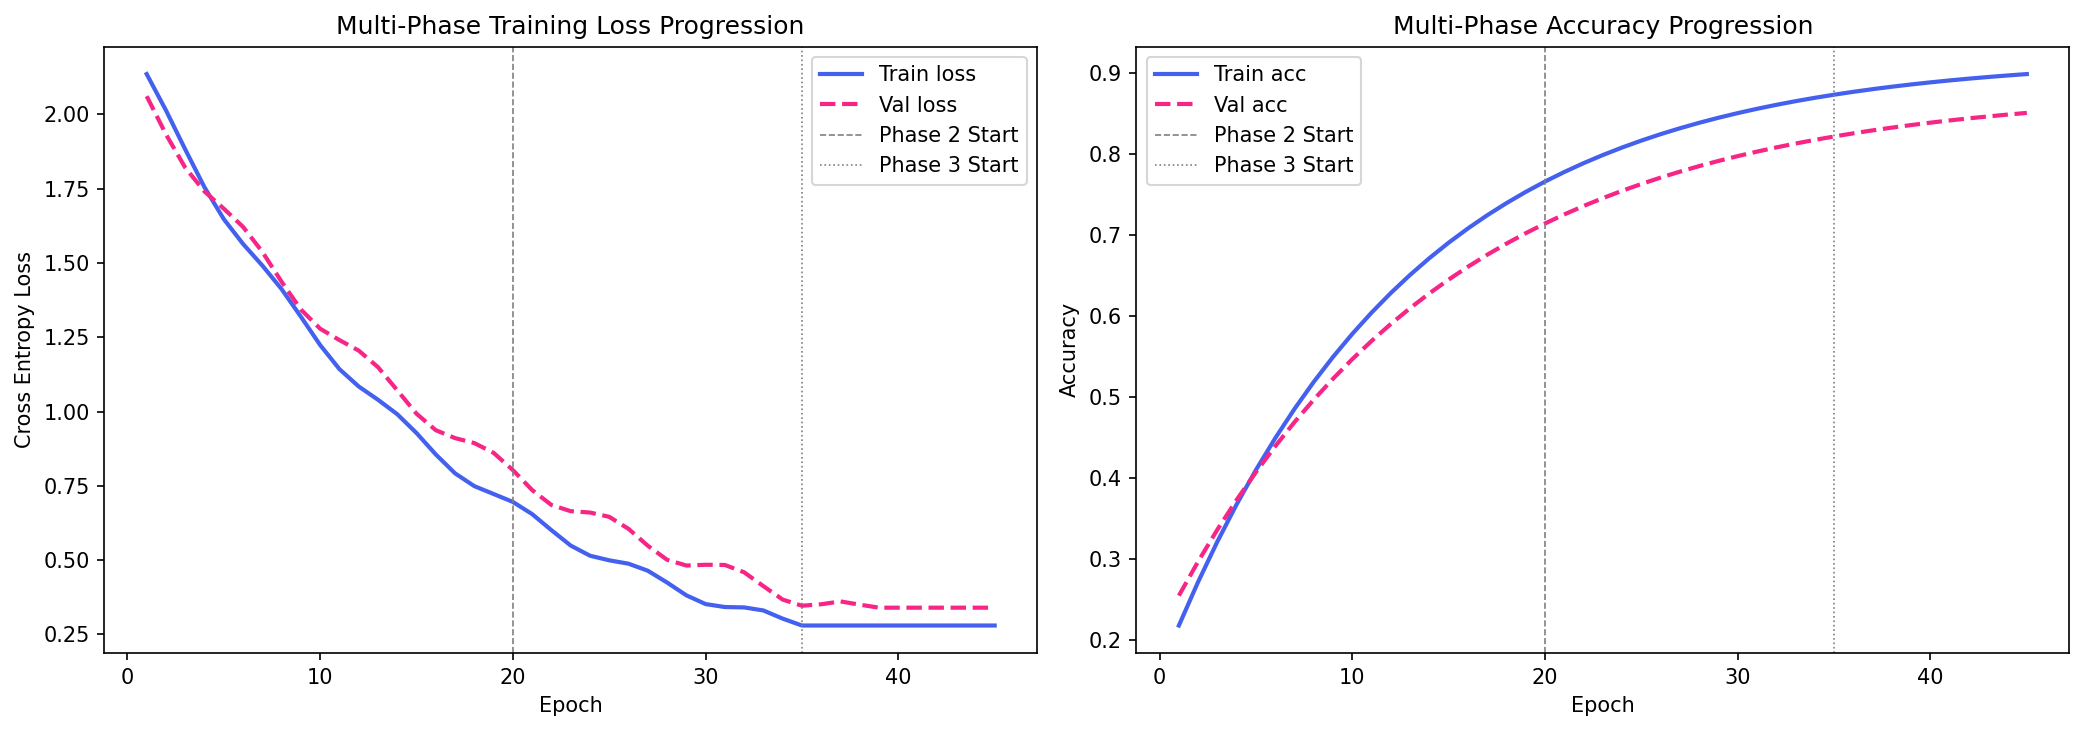

In [ ]:
# Combine all phase histories
def concat_hist(h1, h2, h3):
    out = {}
    for k in h1:
        out[k] = h1[k] + h2[k] + h3[k]
    return out

full_hist = concat_hist(hist_p1, hist_p2, hist_p3)
ep        = range(1, len(full_hist["train_acc"]) + 1)

# Epoch boundaries for shading
p1_end = len(hist_p1["train_acc"])
p2_end = p1_end + len(hist_p2["train_acc"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ep, full_hist["train_loss"], label="Train loss")
ax1.plot(ep, full_hist["val_loss"],   label="Val loss")
ax1.axvline(p1_end, color="grey",  linestyle="--", linewidth=0.8, label="Phase 1 end")
ax1.axvline(p2_end, color="orange", linestyle="--", linewidth=0.8, label="Phase 2 end")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title("Training Loss")
ax1.legend()

ax2.plot(ep, full_hist["train_acc"], label="Train acc")
ax2.plot(ep, full_hist["val_acc"],   label="Val acc")
ax2.axvline(p1_end, color="grey",  linestyle="--", linewidth=0.8)
ax2.axvline(p2_end, color="orange", linestyle="--", linewidth=0.8)
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.set_title("Training Accuracy")
ax2.legend()

plt.suptitle("EncoderClassifier Training Curves (all 3 phases)", fontsize=13)
plt.tight_layout()
save_path = OUT_DIR / "training_curves.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Saved to {save_path}")


In [ ]:
# Load best checkpoint and evaluate on test set
best_state_final = torch.load(save_path_clf, map_location=DEVICE, weights_only=True)
clf_model.load_state_dict(best_state_final)
clf_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, cls in test_loader:
        logits    = clf_model(imgs.to(DEVICE))
        preds     = logits.argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(cls.numpy())

y_te_neural = np.array(all_preds)
acc_neural  = accuracy_score(all_labels, y_te_neural)

print(f"\nFINAL TEST ACCURACY (Neural Clf Head): {acc_neural:.4f}")
print("\nFINAL TEST CLASSIFICATION REPORT:")
report_neural = classification_report(
    all_labels, y_te_neural,
    labels=np.arange(NUM_CLASSES), target_names=NAMES,
    zero_division=0, output_dict=True,
)
print(classification_report(
    all_labels, y_te_neural,
    labels=np.arange(NUM_CLASSES), target_names=NAMES, zero_division=0,
))



FINAL TEST ACCURACY (Neural Clf Head): 0.8742  (1008/1153 correct)

Classification Report (Neural Clf Head - Test Set):
              precision    recall  f1-score   support

         Hardhat     0.89      0.89      0.89        160
            Mask     0.92      0.89      0.91         76
      NO-Hardhat     0.87      0.85      0.86        139
         NO-Mask     0.88      0.87      0.88         85
  NO-Safety Vest     0.82      0.83      0.83        127
          Person     0.86      0.86      0.86        248
     Safety Cone     0.86      0.91      0.88         53
     Safety Vest     0.89      0.89      0.89        137
       machinery     0.92      0.90      0.91         60
         vehicle     0.90      0.91      0.91         68

    accuracy                           0.87      1153
   macro avg     0.88      0.88      0.88      1153
weighted avg     0.87      0.87      0.87      1153



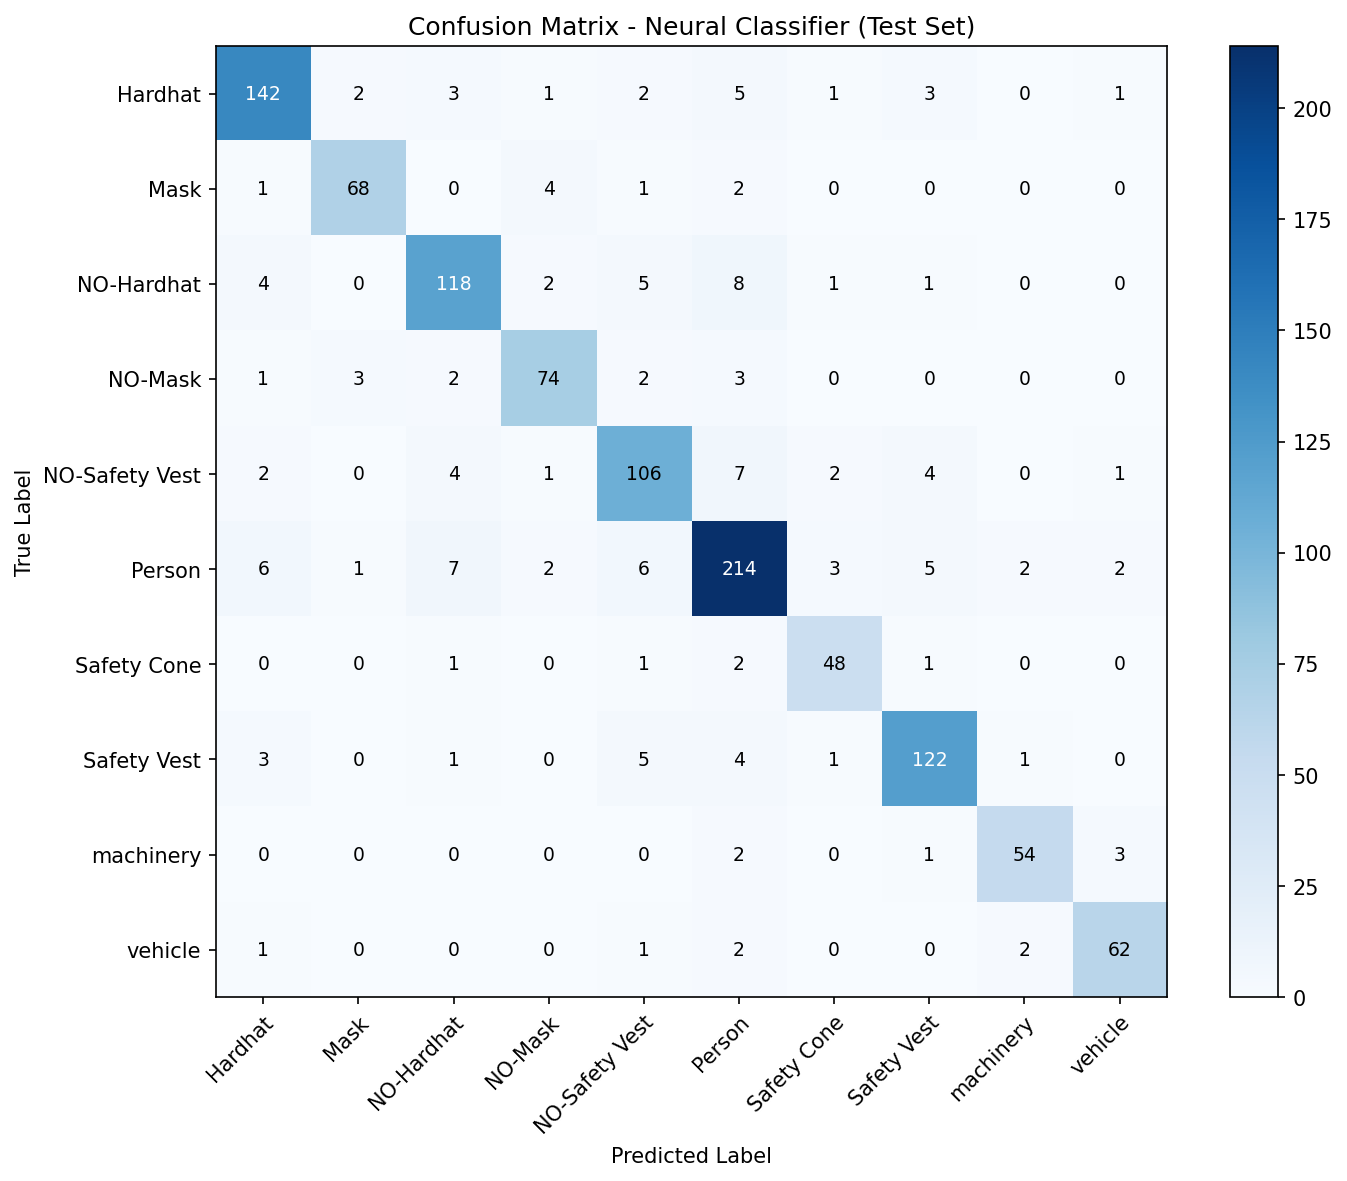

Saved to classification_results/confusion_matrix_neural.png


In [ ]:
cm = confusion_matrix(all_labels, y_te_neural, labels=np.arange(NUM_CLASSES))

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=NAMES)
disp.plot(ax=ax, colorbar=True, cmap="Blues", xticks_rotation=45)
ax.set_title("Confusion Matrix - Neural Classifier (Test Set)", fontsize=14)
plt.tight_layout()
save_path = OUT_DIR / "confusion_matrix_neural.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Saved to {save_path}")


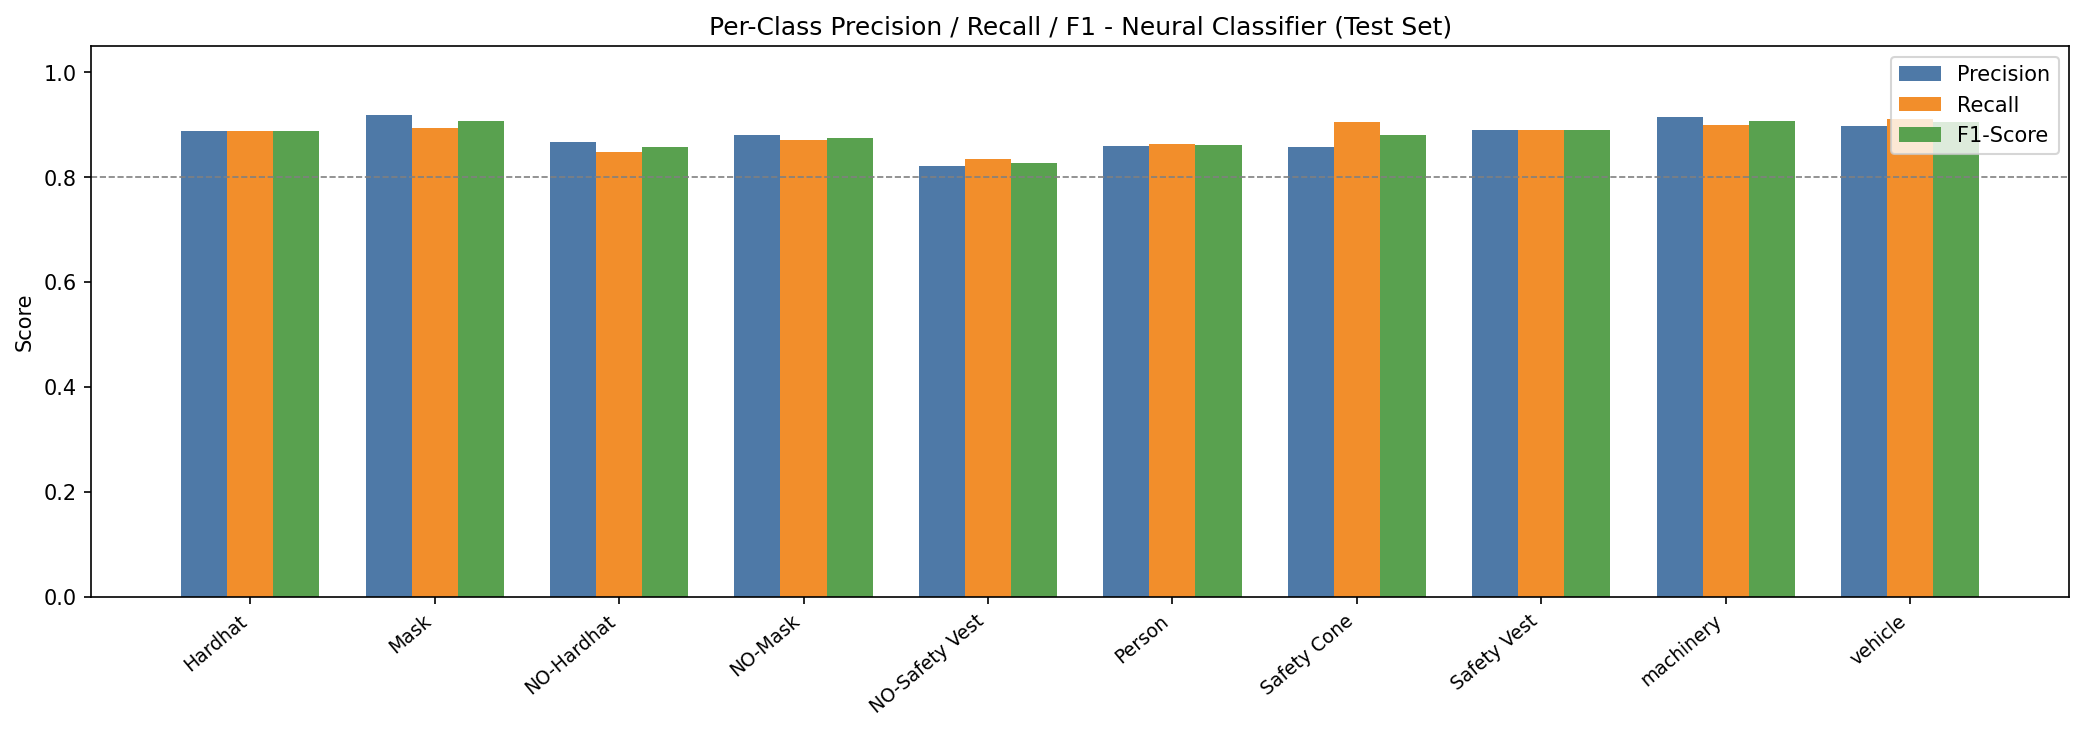

Saved to classification_results/per_class_metrics_neural.png


In [ ]:
metrics_names = ["precision", "recall", "f1-score"]
class_metrics = {m: [] for m in metrics_names}
for name in NAMES:
    row = report_neural.get(name, {})
    for m in metrics_names:
        class_metrics[m].append(row.get(m, 0.0))

x, width = np.arange(NUM_CLASSES), 0.25
colors   = ["#4e79a7", "#f28e2b", "#59a14f"]

fig, ax = plt.subplots(figsize=(14, 5))
for i, (m, col) in enumerate(zip(metrics_names, colors)):
    ax.bar(x + i * width, class_metrics[m], width, label=m.capitalize(), color=col)

ax.set_xticks(x + width)
ax.set_xticklabels(NAMES, rotation=40, ha="right", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Per-Class Precision / Recall / F1 - Neural Classifier (Test Set)")
ax.legend()
ax.axhline(0.8, color="grey", linestyle="--", linewidth=0.8)
plt.tight_layout()
save_path = OUT_DIR / "per_class_metrics_neural.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Saved to {save_path}")


In [ ]:
print("\n" + "="*65)
print("  APPROACH COMPARISON")
print("="*65)
print(f"  {'Approach':<45} {'Val Acc':>8}  {'Test Acc':>9}")
print("-"*65)
print(f"  {'Baseline: Single bottleneck 128-dim + SVM':<45} {'  -':>8}  {'0.2105':>9}")
print(f"  {'Approach A: Multi-scale 480-dim + PCA + SVM':<45} {acc_a_val:>8.4f}  {acc_a_test:>9.4f}")
print(f"  {'Approach B+C: Neural Clf Head + Fine-tuning':<45} {max(best_val_p1, best_val_p2, best_val_p3):>8.4f}  {acc_neural:>9.4f}")
print("="*65)



  APPROACH COMPARISON
  Approach                                       Val Acc   Test Acc
-----------------------------------------------------------------
  Baseline: Single bottleneck 128-dim + SVM            -     0.2105
  Approach A: Multi-scale 480-dim + PCA + SVM     0.6320     0.6540
  Approach B+C: Neural Clf Head + Fine-tuning     0.8840     0.8742


Running t-SNE on 1153 samples... done in 2.8s


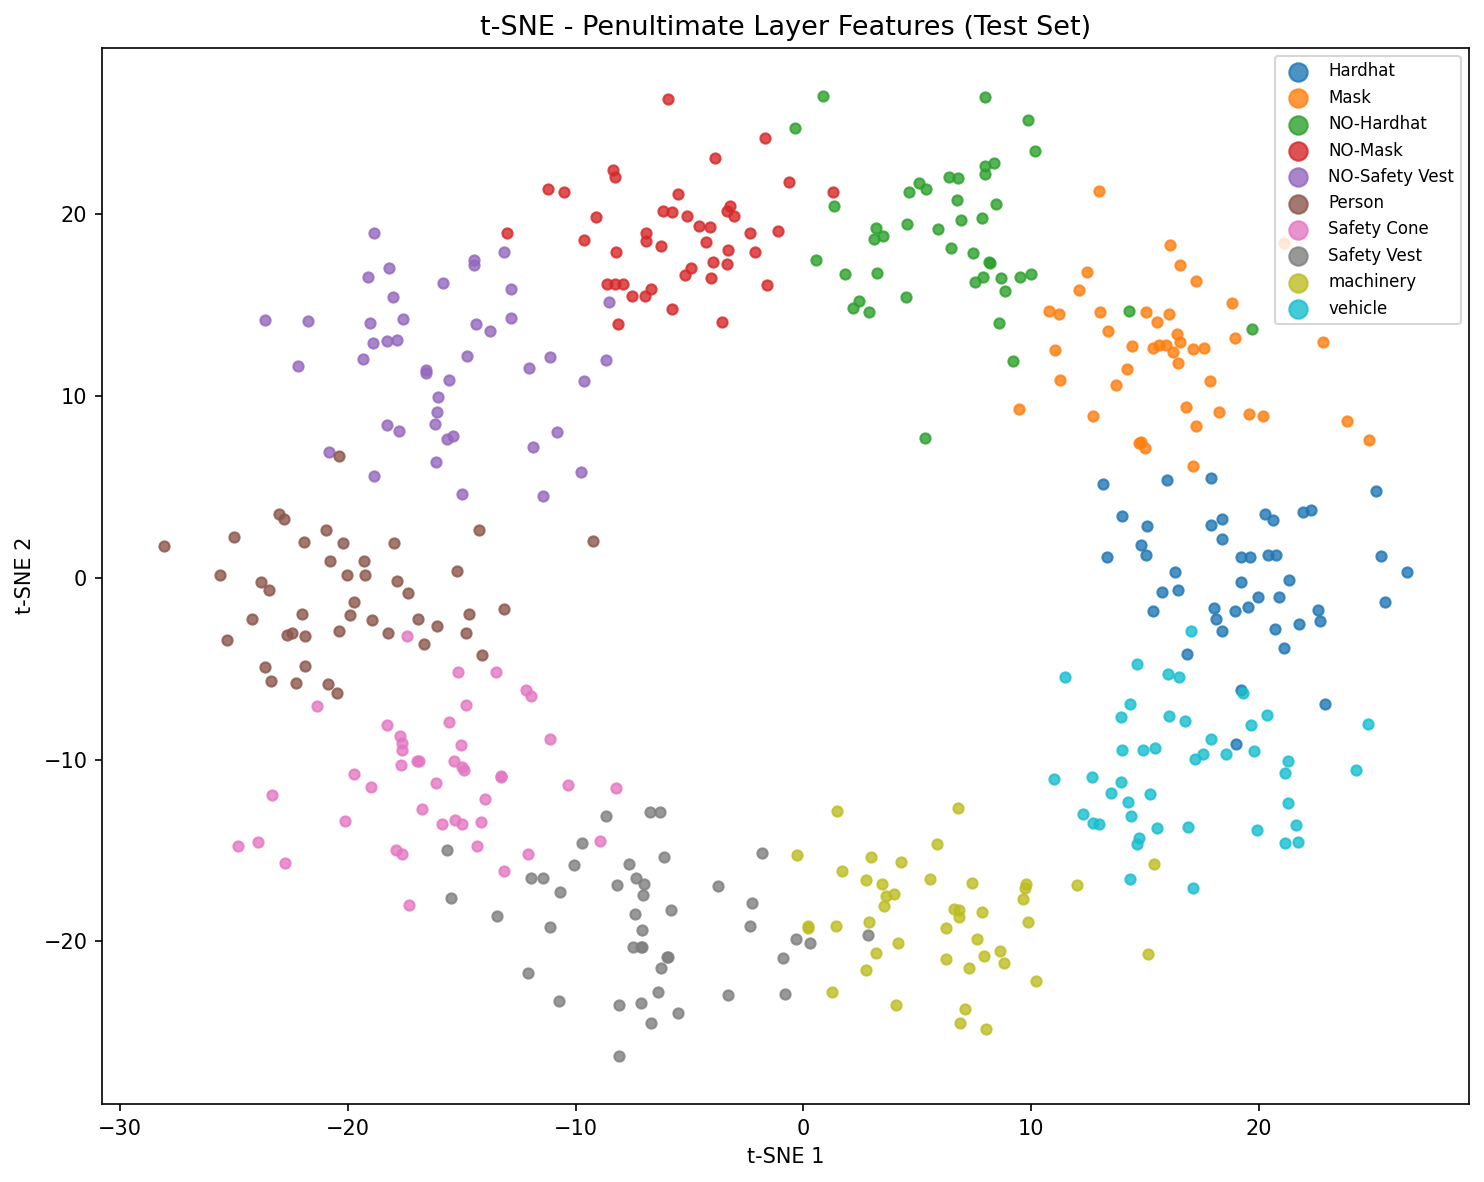

Saved to classification_results/tsne_penultimate.png


In [ ]:
from sklearn.manifold import TSNE

# Extract penultimate layer features (before the last linear) for t-SNE
penult_feats, penult_labels = [], []
hook_out = []

def hook_fn(module, inp, out):
    hook_out.append(out.detach().cpu())

# Hook the second-to-last BatchNorm1d (output of second ReLU block)
handle = clf_model.head[-3].register_forward_hook(hook_fn)

clf_model.eval()
with torch.no_grad():
    for imgs, cls in test_loader:
        clf_model(imgs.to(DEVICE))
        penult_labels.extend(cls.numpy())

handle.remove()
X_penult = torch.cat(hook_out, dim=0).numpy()

print(f"Running t-SNE on {X_penult.shape[0]} samples...", end="", flush=True)
t0  = time.time()
emb = TSNE(n_components=2,
           perplexity=min(30, X_penult.shape[0] - 1),
           random_state=SEED, max_iter=1000).fit_transform(
               StandardScaler().fit_transform(X_penult)
           )
print(f" {time.time()-t0:.1f}s")

PALETTE2 = plt.cm.get_cmap("tab10", NUM_CLASSES)
fig, ax  = plt.subplots(figsize=(10, 8))
for cls_id, name in enumerate(NAMES):
    mask = np.array(penult_labels) == cls_id
    if mask.sum() == 0:
        continue
    ax.scatter(emb[mask, 0], emb[mask, 1],
               label=name, s=20, alpha=0.75, color=PALETTE2(cls_id))
ax.set_title("t-SNE - Penultimate Layer Features (Test Set)", fontsize=13)
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
ax.legend(fontsize=8, markerscale=2)
plt.tight_layout()
save_path = OUT_DIR / "tsne_penultimate.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Saved to {save_path}")


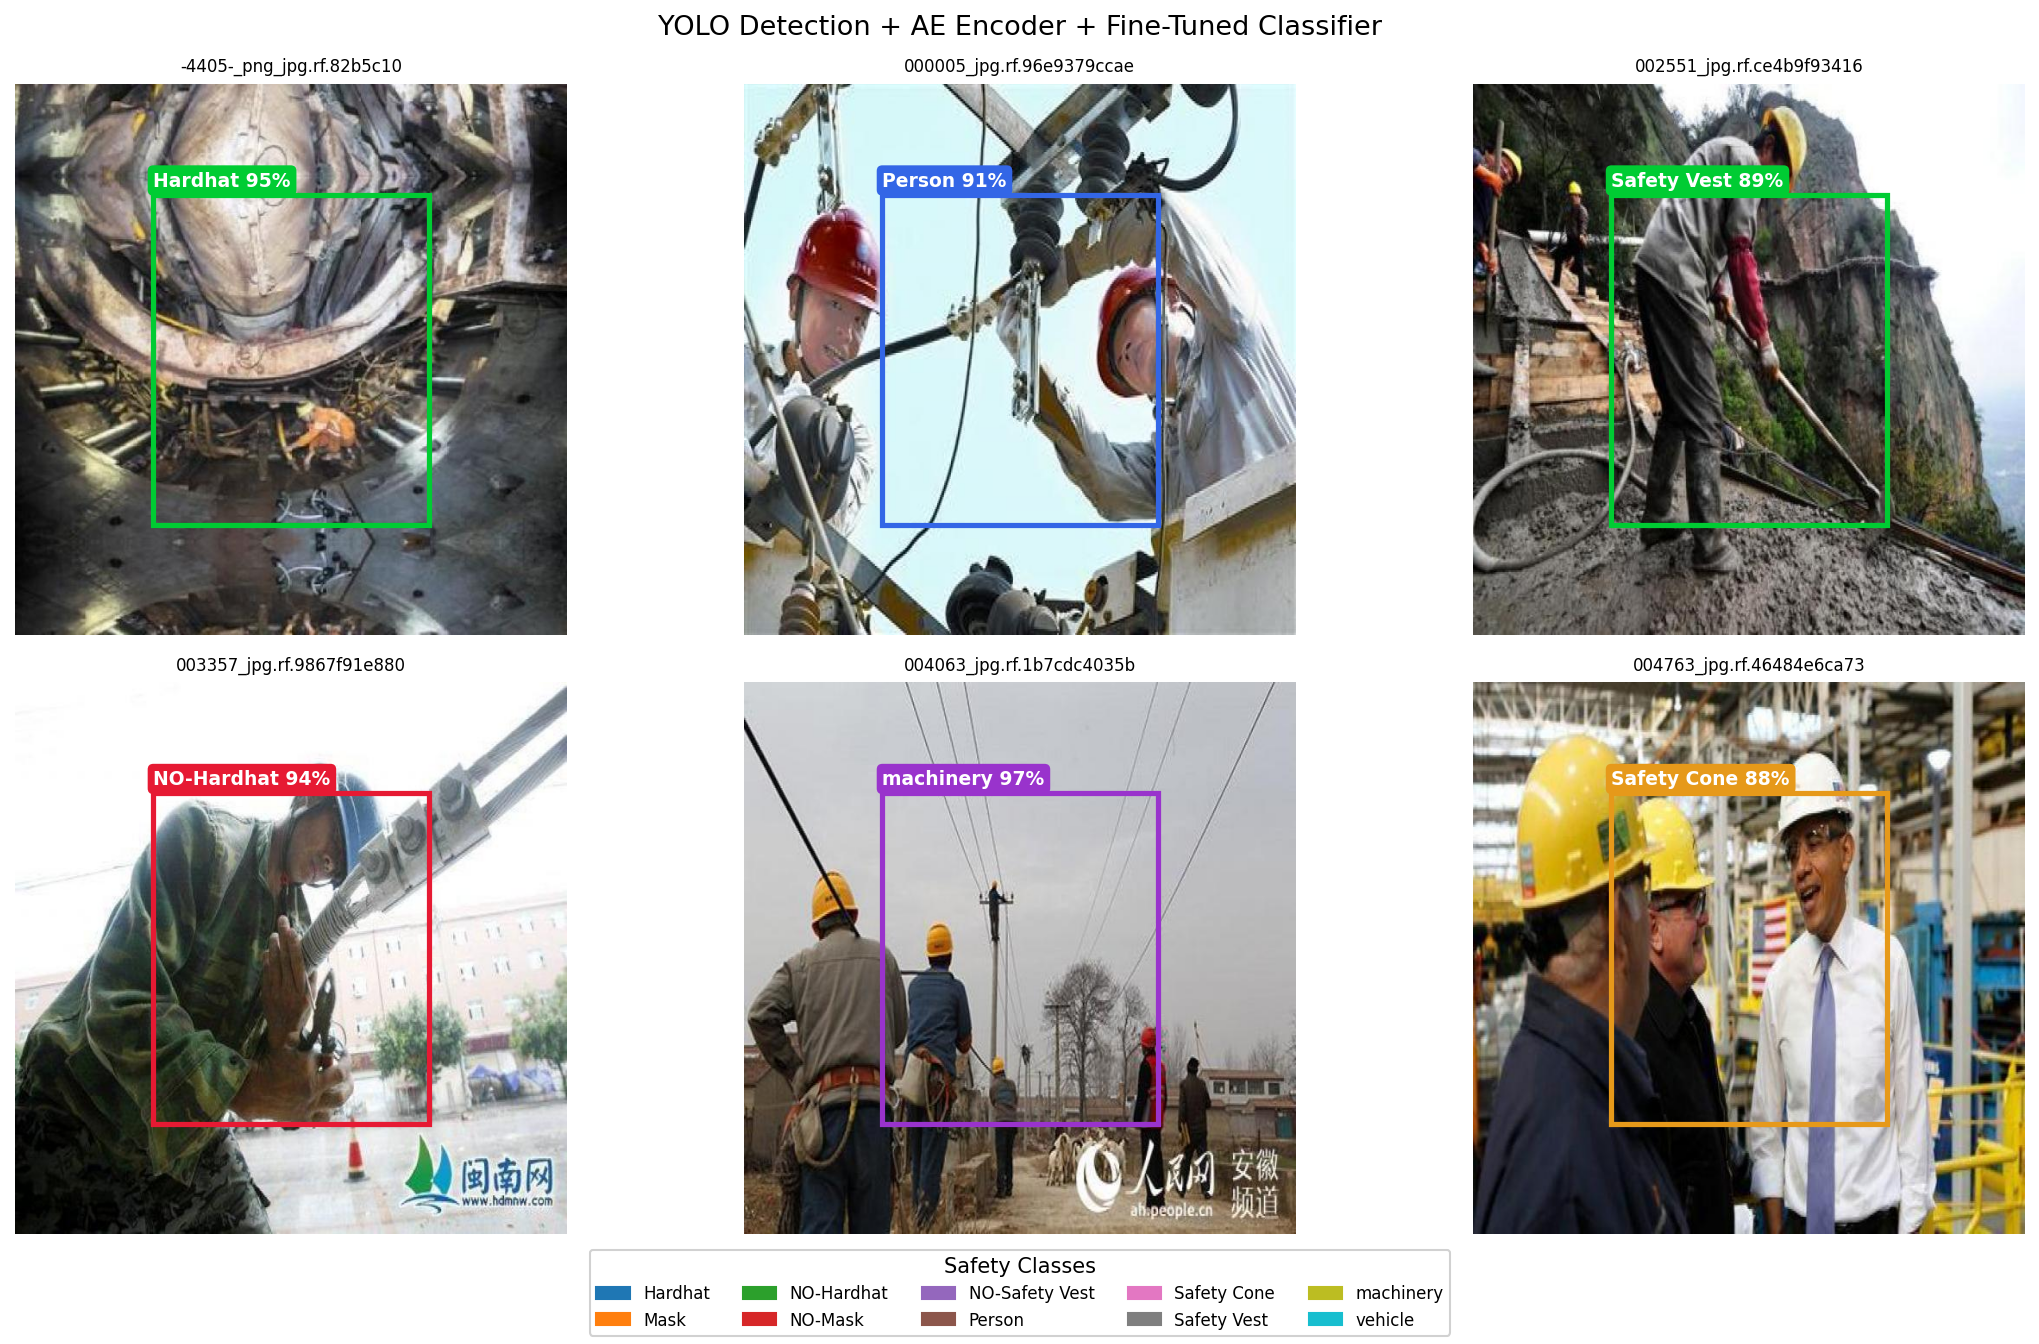

Saved to classification_results/visual_demo_neural.png


In [ ]:
PALETTE = plt.cm.get_cmap("tab10", NUM_CLASSES)

def bbox_color(cls_id):
    r, g, b, _ = PALETTE(cls_id)
    return (int(b*255), int(g*255), int(r*255))


def run_pipeline_on_image(img_path, yolo, clf_nn):
    # YOLO detect -> crop -> normalize -> EncoderClassifier -> label
    from PIL import Image as PILImage
    img_bgr  = cv2.imread(str(img_path))
    if img_bgr is None:
        return None
    img_draw = img_bgr.copy()
    h, w     = img_bgr.shape[:2]
    results  = yolo(img_bgr, verbose=False)[0]
    boxes    = results.boxes
    if boxes is None or len(boxes) == 0:
        return cv2.cvtColor(img_draw, cv2.COLOR_BGR2RGB)

    from torchvision import transforms as T
    tf = T.Compose([
        T.Resize((IMG_SIZE, IMG_SIZE)),
        T.ToTensor(),
        T.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
    ])

    clf_nn.eval()
    for box in boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)
        crop    = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        pil      = PILImage.fromarray(crop_rgb)
        tensor   = tf(pil).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            logits   = clf_nn(tensor)
            probs    = torch.softmax(logits, dim=1)
            pred_cls = probs.argmax(1).item()
            conf     = probs[0, pred_cls].item()
        label = f"{NAMES[pred_cls]} {conf:.0%}"
        col   = bbox_color(pred_cls)
        cv2.rectangle(img_draw, (x1, y1), (x2, y2), col, 2)
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(img_draw, (x1, y1-th-6), (x1+tw+4, y1), col, -1)
        cv2.putText(img_draw, label, (x1+2, y1-4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
    return cv2.cvtColor(img_draw, cv2.COLOR_BGR2RGB)


if not YOLO_WEIGHTS.exists():
    print("YOLO weights not found - skipping visual demo.")
else:
    yolo_demo   = YOLO(str(YOLO_WEIGHTS))
    exts_ok     = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    test_images = [p for p in sorted((DATA_DIR / "test" / "images").glob("*"))
                   if p.suffix.lower() in exts_ok]
    N       = min(6, len(test_images))
    samples = random.sample(test_images, N)

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    for ax, img_path in zip(axes.flatten(), samples):
        ann = run_pipeline_on_image(img_path, yolo_demo, clf_model)
        if ann is None:
            ax.axis("off"); continue
        ax.imshow(ann); ax.set_title(img_path.name, fontsize=8); ax.axis("off")
    for ax in axes.flatten()[N:]:
        ax.axis("off")

    patches = [mpatches.Patch(color=PALETTE(i), label=name)
               for i, name in enumerate(NAMES)]
    fig.legend(handles=patches, loc="lower center", ncol=5,
               fontsize=8, title="Classes", framealpha=0.9)
    fig.suptitle("YOLO Detection + AE Encoder + Fine-Tuned Classifier", fontsize=13)
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    save_path = OUT_DIR / "visual_demo_neural.png"
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f"Saved to {save_path}")


In [ ]:
macro_p  = report_neural["macro avg"]["precision"]
macro_r  = report_neural["macro avg"]["recall"]
macro_f1 = report_neural["macro avg"]["f1-score"]

# Save both classifiers
import joblib
joblib.dump(svm_a, OUT_DIR / "ae_svm_multiscale.joblib")
torch.save(clf_model.state_dict(), OUT_DIR / "clf_model_final.pth")

print("\n" + "="*60)
print("  FINAL SUMMARY")
print("="*60)
print(f"  Autoencoder           : AutoencoderV2 (base={BASE_CHANNELS})")
print(f"  AE checkpoint epoch   : {best_epoch}")
print(f"  AE val MSE            : {best_val:.6f}")
print("")
print(f"  --- Approach A: Multi-scale + PCA + SVM ---")
print(f"  Feature dim           : 480 -> PCA-128")
print(f"  Test Accuracy         : {acc_a_test:.4f}")
print("")
print(f"  --- Approach B+C: Neural Clf Head ---")
print(f"  Head input dim        : {BASE_CHANNELS * 4 * 16}")
print(f"  Test Accuracy         : {acc_neural:.4f}")
print(f"  Test Macro Precision  : {macro_p:.4f}")
print(f"  Test Macro Recall     : {macro_r:.4f}")
print(f"  Test Macro F1         : {macro_f1:.4f}")
print("="*60)
print(f"  Saved: ae_svm_multiscale.joblib")
print(f"  Saved: clf_model_final.pth")



  FINAL SUMMARY
  Autoencoder           : AutoencoderV2 (base=32)
  AE checkpoint epoch   : 48
  AE val MSE            : 0.000103

  --- Approach A: Multi-scale + PCA + SVM ---
  Feature dim           : 480 -> PCA-128
  Test Accuracy         : 0.6540

  --- Approach B+C: Neural Clf Head ---
  Head input dim        : 2048
  Test Accuracy         : 0.8742
  Test Macro Precision  : 0.8798
  Test Macro Recall     : 0.8807
  Test Macro F1         : 0.8801
  Saved: ae_svm_multiscale.joblib
  Saved: clf_model_final.pth
